In [ ]:
!pip install plotly

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder,PolynomialFeatures
from sklearn.metrics import accuracy_score
import plotly.graph_objects as go


# **LinearRegression**

Slope (m): 0.43238016300594
Intercept (b): 12.427407100428237


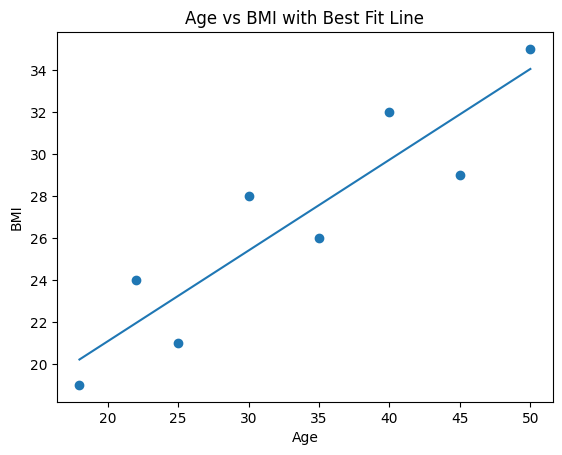

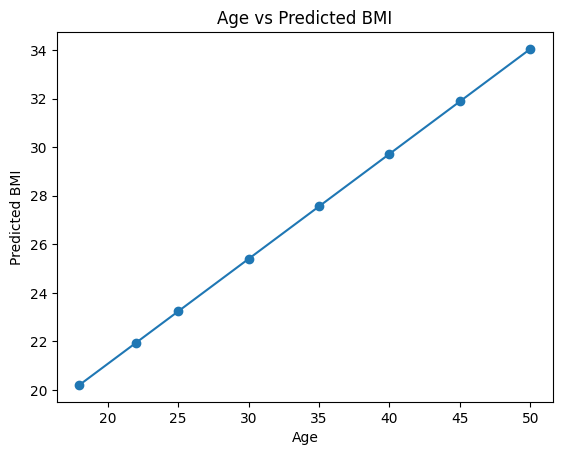

In [ ]:

# Sample Data
age = np.array([[18], [22], [25], [30], [35], [40], [45], [50]])
bmi = np.array([19, 24, 21, 28, 26, 32, 29, 35])

# Create and train model
model = LinearRegression()
model.fit(age, bmi)         #age→feature,bmi→ target

# Predict BMI
bmi_pred = model.predict(age)

# Print slope and intercept
print("Slope (m):", model.coef_[0])
print("Intercept (b):", model.intercept_)

# -------- Plot: Actual Data + Best Fit Line --------
plt.scatter(age, bmi)              # plot age,bmi data
plt.title("Age vs BMI with Best Fit Line")       #give title to the graph
plt.plot(age, bmi_pred)      # plot best-fit regression line
plt.xlabel("Age")            #write 'Age' in x_axis
plt.ylabel("BMI")            #write 'Bmi' in x_axis
plt.show()                   #prints the graph

# -------- Plot 2: Age vs Predicted BMI --------
plt.figure()
plt.scatter(age, bmi_pred)      # plot age,bmi_pred data
plt.plot(age, bmi_pred)         # plot best-fit regression line
plt.xlabel("Age")
plt.ylabel("Predicted BMI")
plt.title("Age vs Predicted BMI")
plt.show()


# **Multiple LinearRegression**

In [ ]:


# Sample dataset
data = {
    "Size_sqft": [1000, 1500, 2000, 2500, 3000],
    "Age": [10, 8, 5, 3, 1],
    "price": [200000, 250000, 320000, 400000, 500000]
}

df = pd.DataFrame(data)

X = df[["Size_sqft", "Age"]]
y = df["price"]

model = LinearRegression()
model.fit(X, y)

pred_price = model.predict(X)

# Create meshgrid for plane
size_range = np.linspace(df["Size_sqft"].min(), df["Size_sqft"].max(), 20)
age_range = np.linspace(df["Age"].min(), df["Age"].max(), 20)
size_grid, age_grid = np.meshgrid(size_range, age_range)

plane_points = np.c_[size_grid.ravel(), age_grid.ravel()]
price_plane = model.predict(plane_points)
price_grid = price_plane.reshape(size_grid.shape)

# -------- FIGURE 1 --------
fig1 = go.Figure()

fig1.add_trace(go.Scatter3d(
    x=df["Size_sqft"],
    y=df["Age"],
    z=y,
    mode='markers',
    marker=dict(size=6, color='blue'),
    name='Actual Price'
))

fig1.add_trace(go.Surface(
    x=size_grid,
    y=age_grid,
    z=price_grid,
    opacity=0.5,
    colorscale='Viridis',
    name='Regression Plane'
))

fig1.update_layout(
    title="Actual Price + Regression Plane",
    scene=dict(
        xaxis_title='Size_sqft',
        yaxis_title='Age',
        zaxis_title='Price'
    )
)

fig1.show()




# -------- FIGURE 2 --------
fig2 = go.Figure()

fig2.add_trace(go.Scatter3d(
    x=df["Size_sqft"],
    y=df["Age"],
    z=pred_price,
    mode='markers',
    marker=dict(size=6, color='green'),
    name='Predicted Price'
))

fig2.add_trace(go.Surface(
    x=size_grid,
    y=age_grid,
    z=price_grid,
    opacity=0.5,
    colorscale='Viridis',
    name='Regression Plane'
))

fig2.update_layout(
    title="Predicted Price + Regression Plane",
    scene=dict(
        xaxis_title='Size_sqft',
        yaxis_title='Age',
        zaxis_title='Predicted Price'
    )
)

fig2.show()


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LinearRegression was fitted with feature names



# **PolynomialLinearRegression**

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but PolynomialFeatures was fitted with feature names



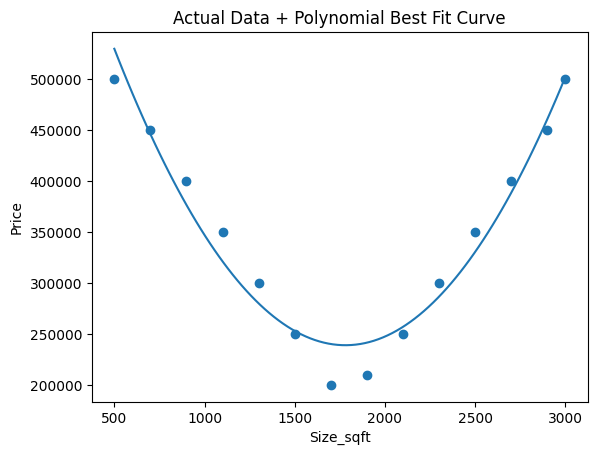

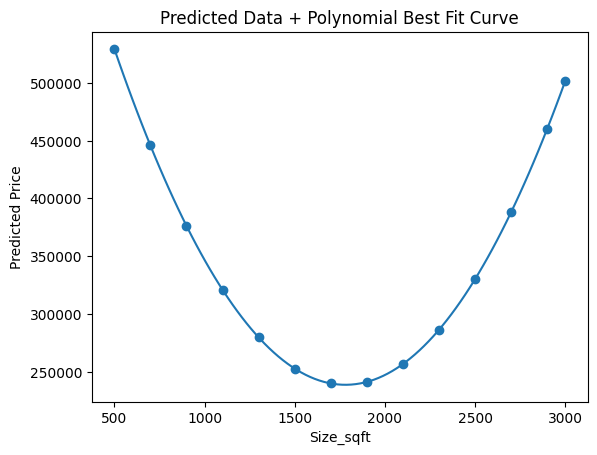

In [ ]:

# Sample dataset
df = pd.DataFrame({
    "Size_sqft": [500, 700, 900, 1100, 1300, 1500, 1700, 1900, 2100, 2300, 2500, 2700, 2900, 3000],
    "price":     [500000, 450000, 400000, 350000, 300000, 250000, 200000, 210000, 250000, 300000, 350000, 400000, 450000, 500000]
})


X = df[["Size_sqft"]]
y = df["price"]

# Create polynomial features (degree 2)
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

# Train model
model = LinearRegression()
model.fit(X_poly, y)

# Predictions
y_pred = model.predict(X_poly)

# Create smooth curve
X_range = np.linspace(X.min(), X.max(), 100)
X_range_poly = poly.transform(X_range)
y_range_pred = model.predict(X_range_poly)

# ----------- Graph 1: Actual Data + Polynomial Curve -----------
plt.figure()
plt.scatter(X, y)
plt.plot(X_range, y_range_pred)

plt.title("Actual Data + Polynomial Best Fit Curve")
plt.xlabel("Size_sqft")
plt.ylabel("Price")
plt.show()


# ----------- Graph 2: Predicted Data + Polynomial Curve -----------
plt.figure()
plt.scatter(X, y_pred)
plt.plot(X_range, y_range_pred)

plt.title("Predicted Data + Polynomial Best Fit Curve")
plt.xlabel("Size_sqft")
plt.ylabel("Predicted Price")
plt.show()


# **LogisticRegression**

**Simple**

   Age  MonthlyCharges  SupportCalls  Churn
0   25            2000             1      0
1   30            2500             2      0
2   45            3000             4      1
3   35            2800             1      0
4   50            3500             5      1
5   23            1800             0      0
6   40            2900             3      1
7   60            4000             6      1


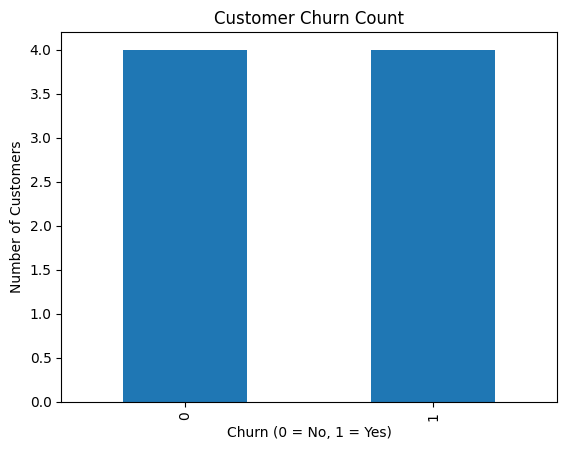


Predictions:
   Age  MonthlyCharges  SupportCalls  Churn  Predicted_Churn
0   25            2000             1      0                0
1   30            2500             2      0                0
2   45            3000             4      1                1
3   35            2800             1      0                0
4   50            3500             5      1                1
5   23            1800             0      0                0
6   40            2900             3      1                1
7   60            4000             6      1                1
**************************************************

Model Accuracy: 1.0
**************************************************
Enter Age: 23
Enter Monthly Charges: 2300
Enter Support Calls: 7

New Customer Prediction:
Customer is likely to stay ✅


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:

# Create dataset
df = pd.DataFrame({
    "Age": [25, 30, 45, 35, 50, 23, 40, 60],
    "MonthlyCharges": [2000, 2500, 3000, 2800, 3500, 1800, 2900, 4000],
    "SupportCalls": [1, 2, 4, 1, 5, 0, 3, 6],
    "Churn": [0, 0, 1, 0, 1, 0, 1, 1]    # 1 = Churn, 0 = Not Churn
})


# Display dataset
print(df)

# Visualize churn
df["Churn"].value_counts().plot(kind="bar")
#df["Churn"]→Select Churn column
#.value_counts()→Counts how many times each value appears i.e 0 → 4,1 → 4
#.plot(kind="bar")→Converts those counts into a bar chart
plt.title("Customer Churn Count")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

# Prepare features and target
X = df[["Age", "MonthlyCharges", "SupportCalls"]]
y = df["Churn"]

# Train Logistic Regression model
model = LogisticRegression()
model.fit(X, y)

# Make predictions on existing data
df["Predicted_Churn"] = model.predict(X)
#add new columns named Predicted_Churn in df and predit churn using values of x
#here it's trying to predit from past data
print("\nPredictions:")
print(df)

# Model accuracy
accuracy = accuracy_score(y, df["Predicted_Churn"])
#check accuray of the model
#y→actual data, df["Predicted_Churn"] →predicted data
print('*'*50)
print("\nModel Accuracy:", accuracy)
print('*'*50)

# Predict for new customer
a = int(input('Enter Age: '))
c = int(input('Enter Monthly Charges: '))
s = int(input('Enter Support Calls: '))
new_customer = [[a, c, s]]
prediction = model.predict(new_customer)

print("\nNew Customer Prediction:")
print("Customer is likely to churn ❌" if prediction[0] == 1 else "Customer is likely to stay ✅")


# **DecisionTreeClassifier**

    Outlook Temperature Humidity    Wind Play
0     Sunny         Hot     High    Weak   No
1     Sunny         Hot     High  Strong   No
2  Overcast         Hot     High    Weak  Yes
3      Rain        Mild     High    Weak  Yes
4      Rain        Cool   Normal    Weak  Yes
5      Rain        Cool   Normal  Strong   No
6  Overcast        Mild   Normal  Strong  Yes
7     Sunny        Cool     High    Weak   No
************************************************************
************************************************************
   Outlook  Temperature  Humidity  Wind  Play  Predicted_Play
0        2            1         0     1     0               0
1        2            1         0     0     0               0
2        0            1         0     1     1               1
3        1            2         0     1     1               1
4        1            0         1     1     1               1
5        1            0         1     0     0               0
6        0            2       

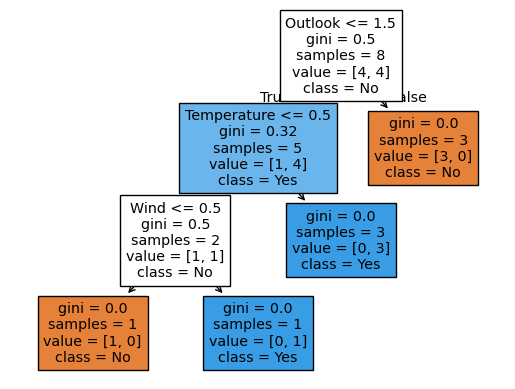

In [ ]:

# Sample dataset
df = pd.DataFrame({
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain', 'Overcast', 'Sunny'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool', 'Mild', 'Cool'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal', 'Normal', 'High'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak'],
    'Play': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No']
})

print(df)
print('*'*60)
print('*'*60)
# Encoded
df_encoded = df.copy()

le = LabelEncoder()
'''LabelEncoder()→creates an empty encoder object(think it like an empty note book)
    .fit()→put all unique values in that book
    transform()→convert those values into numbers
'''

for column in df_encoded.columns:
    df_encoded[column] = le.fit_transform(df_encoded[column])
'''.fit()→Learns all unique values in that column.Example for Outlook: ['Sunny', 'Overcast', 'Rain']
    transform()→Converts unique values into numbers
                Example:
                        Overcast → 0
                        Rain     → 1
                        Sunny    → 2
'''

# Features and target
x = df_encoded[['Outlook','Temperature','Humidity','Wind']]
y = df_encoded['Play']

# Create Decision Tree model
model = DecisionTreeClassifier(random_state=42)
model.fit(x, y)

# Make predictions
df_encoded["Predicted_Play"] = model.predict(x)
print(df_encoded)

# Plot the DecisionTree
plot_tree(model, feature_names=x.columns,class_names=["No", "Yes"], filled=True,)
'''plot_tree()→draws the tree structure as a figure
   class_names=["No", "Yes"]→convert 0 into 'No' and 1 into 'Yes'
   filled=True→fills the nodes with colors
'''
plt.show()

# **RandomForestClassifier**

    Outlook Temperature Humidity    Wind Play
0     Sunny         Hot     High    Weak   No
1     Sunny         Hot     High  Strong   No
2  Overcast         Hot     High    Weak  Yes
3      Rain        Mild     High    Weak  Yes
4      Rain        Cool   Normal    Weak  Yes
5      Rain        Cool   Normal  Strong   No
6  Overcast        Mild   Normal  Strong  Yes
7     Sunny        Cool     High    Weak   No
************************************************************
************************************************************
   Outlook  Temperature  Humidity  Wind  Play  Predicted_Play
0        2            1         0     1     0               0
1        2            1         0     0     0               0
2        0            1         0     1     1               1
3        1            2         0     1     1               1
4        1            0         1     1     1               1
5        1            0         1     0     0               0
6        0            2       

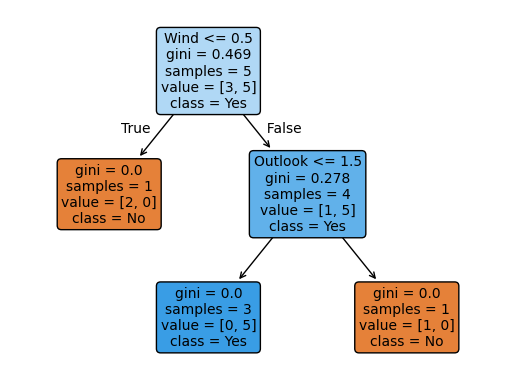

In [ ]:

# Sample dataset
df = pd.DataFrame({
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain', 'Overcast', 'Sunny'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool', 'Mild', 'Cool'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal', 'Normal', 'High'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak'],
    'Play': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No']
})

print(df)
print("*"*60)
print("*"*60)

# Encode the data
df_encoded = df.copy()
le = LabelEncoder()

for column in df_encoded.columns:
    df_encoded[column] = le.fit_transform(df_encoded[column])

# Features and target
X = df_encoded[['Outlook','Temperature','Humidity','Wind']]
y = df_encoded['Play']

# Create Random Forest model
model = RandomForestClassifier(
    n_estimators=10,   # number of trees
    random_state=42
)

model.fit(X, y)

# Predictions
df_encoded["Predicted_Play"] = model.predict(X)

print(df_encoded)

# Plot the RandomForestClassifier
plot_tree(model.estimators_[0],
          feature_names=X.columns,
          class_names=["No", "Yes"],
          filled=True,
          rounded=True,
          fontsize=10)
plt.show()
